## Import libraries

In [2]:
import re
import html
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.19.0


## 1. Text Data Preparation

In [3]:
NUM_WORDS = 10000

(X_train_raw, y_train), (X_test_raw, y_test) = imdb.load_data(
    num_words=NUM_WORDS
)

y_train = np.asarray(y_train)
y_test = np.asarray(y_test)

print("Training reviews:", len(X_train_raw))
print("Testing reviews:", len(X_test_raw))
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)
print("Classes:", np.unique(y_train))

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
Training reviews: 25000
Testing reviews: 25000
Training labels: (25000,)
Testing labels: (25000,)
Classes: [0 1]


,Number of reviews
Positive,25000
Negative,25000


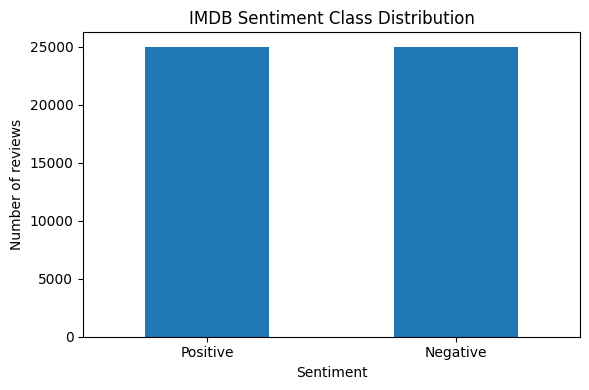

In [4]:
label_counts = pd.Series(
    np.concatenate([y_train, y_test])
).map({0: "Negative", 1: "Positive"}).value_counts()

display(label_counts.to_frame("Number of reviews"))

plt.figure(figsize=(6, 4))
label_counts.plot(kind="bar")
plt.title("IMDB Sentiment Class Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [5]:
word_index = imdb.get_word_index()
index_to_word = {index + 3: word for word, index in word_index.items()}
index_to_word[0] = "<PAD>"
index_to_word[1] = "<START>"
index_to_word[2] = "<UNK>"
index_to_word[3] = "<UNUSED>"

def decode_review(sequence):
    return " ".join(index_to_word.get(int(i), "<UNK>") for i in sequence
                    if int(i) > 3)

train_text = [decode_review(review) for review in X_train_raw]
test_text = [decode_review(review) for review in X_test_raw]

print("Example decoded review:")
print(train_text[0][:1000])
print("\nLabel:", "Positive" if y_train[0] == 1 else "Negative")

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Example decoded review:
this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert is an amazing actor and now the same being director father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for and would recommend it to everyone to watch and the fly fishing was amazing really cried at the end it was so sad and you know what they say if you cry at a film it must have been good and this definitely was also to the two little boy's that played the of norman and paul they were just brilliant children are often left out of the list i think because the stars that play them all grown up are such a big profile for the whole film but these children are amazing 

In [ ]:
def clean_text(text):
    text = html.unescape(str(text)).lower()
    text = re.sub(r"<[^>]+>", " ", text)      
    text = re.sub(r"[^a-z\s]", " ", text)      
    text = re.sub(r"\s+", " ", text).strip()  
    return text

train_clean = [clean_text(text) for text in train_text]
test_clean = [clean_text(text) for text in test_text]

print("Original review:\n", train_text[0][:500])
print("\nCleaned review:\n", train_clean[0][:500])

Original review:
 this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert is an amazing actor and now the same being director father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for and would recommend it to everyone to 

Cleaned review:
 this film was just brilliant casting location scenery story direction everyone s really suited the part they played and you could just imagine being there robert is an amazing actor and now the same being director father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for a

In [7]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
preserved_negations = {"no", "nor", "not"}
stop_words = set(ENGLISH_STOP_WORDS) - preserved_negations

def remove_stopwords(text):
    return " ".join(
        word for word in text.split()
        if word not in stop_words
    )

train_no_stop = [remove_stopwords(text) for text in train_clean]
test_no_stop = [remove_stopwords(text) for text in test_clean]

print("Before stopword removal:\n", train_clean[0][:500])
print("\nAfter stopword removal:\n", train_no_stop[0][:500])

Before stopword removal:
 this film was just brilliant casting location scenery story direction everyone s really suited the part they played and you could just imagine being there robert is an amazing actor and now the same being director father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for and would recommend it to everyone to 

After stopword removal:
 film just brilliant casting location scenery story direction s really suited played just imagine robert amazing actor director father came scottish island loved fact real connection film witty remarks film great just brilliant bought film soon released recommend watch fly fishing amazing really cried end sad know say film good definitely little boy s played norman paul just brilliant children left list think stars play grown big profile film c

## 2. Text Representation

In [8]:
BOW_MAX_FEATURES = 5000
bow_vectorizer = CountVectorizer(
    max_features=BOW_MAX_FEATURES,
    stop_words=list(stop_words)
)
X_train_bow = bow_vectorizer.fit_transform(train_clean)
X_test_bow = bow_vectorizer.transform(test_clean)

tfidf_vectorizer = TfidfVectorizer(
    max_features=BOW_MAX_FEATURES,
    stop_words=list(stop_words)
)
X_train_tfidf = tfidf_vectorizer.fit_transform(train_clean)
X_test_tfidf = tfidf_vectorizer.transform(test_clean)

print("BoW train shape:", X_train_bow.shape)
print("BoW test shape:", X_test_bow.shape)
print("TF-IDF train shape:", X_train_tfidf.shape)
print("TF-IDF test shape:", X_test_tfidf.shape)

BoW train shape: (25000, 5000)
BoW test shape: (25000, 5000)
TF-IDF train shape: (25000, 5000)
TF-IDF test shape: (25000, 5000)


In [9]:
sample_bow = pd.DataFrame(
    X_train_bow[:3].toarray(),
    columns=bow_vectorizer.get_feature_names_out()
)
sample_tfidf = pd.DataFrame(
    X_train_tfidf[:3].toarray(),
    columns=tfidf_vectorizer.get_feature_names_out()
)

print("Sample BoW feature matrix:")
display(sample_bow.iloc[:, :15])

print("Sample TF-IDF feature matrix:")
display(sample_tfidf.iloc[:, :15])

Sample BoW feature matrix:


,abandoned,abc,abilities,ability,able,abraham,absence,absent,absolute,absolutely,absurd,absurdity,abuse,abused,abusive
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


Sample TF-IDF feature matrix:


,abandoned,abc,abilities,ability,able,abraham,absence,absent,absolute,absolutely,absurd,absurdity,abuse,abused,abusive
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [10]:
MAX_WORDS = 10000
MAX_LEN = 200
OOV_TOKEN = "<OOV>"

tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token=OOV_TOKEN
)
tokenizer.fit_on_texts(train_clean)

X_train_sequences = tokenizer.texts_to_sequences(train_clean)
X_test_sequences = tokenizer.texts_to_sequences(test_clean)

X_train_pad = pad_sequences(
    X_train_sequences,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)
X_test_pad = pad_sequences(
    X_test_sequences,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

print("Vocabulary size (including OOV):", len(tokenizer.word_index) + 1)
print("Padded training shape:", X_train_pad.shape)
print("Padded testing shape:", X_test_pad.shape)
print("Training labels shape:", y_train.shape)
print("Testing labels shape:", y_test.shape)

Vocabulary size (including OOV): 9650
Padded training shape: (25000, 200)
Padded testing shape: (25000, 200)
Training labels shape: (25000,)
Testing labels shape: (25000,)


In [11]:
sample_index = 0
print("Cleaned review:\n", train_clean[sample_index][:700])
print("\nInteger sequence:\n", X_train_sequences[sample_index][:50])
print("\nPadded sequence (first 50 values):\n", X_train_pad[sample_index][:50])

Cleaned review:
 this film was just brilliant casting location scenery story direction everyone s really suited the part they played and you could just imagine being there robert is an amazing actor and now the same being director father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for and would recommend it to everyone to watch and the fly fishing was amazing really cried at the end it was so sad and you know what they say if you cry at a film it must have been good and this definitely was also to the two little boy s 

Integer sequence:
 [12, 21, 14, 44, 518, 945, 1582, 1352, 64, 452, 295, 16, 66, 3840, 2, 173, 34, 253, 3, 22, 98, 44, 818, 112, 41, 654, 7, 36, 471, 271, 3, 150, 2, 172, 112, 158, 315, 380, 39, 2, 172, 4415, 1078, 15, 536, 38, 11, 444, 2, 191]

Padded sequence (first 50 values):
 

In [12]:
validation_size = int(0.20 * len(X_train_pad))

X_fit = X_train_pad[validation_size:]
y_fit = y_train[validation_size:]

X_val = X_train_pad[:validation_size]
y_val = y_train[:validation_size]

print("Model training samples:", X_fit.shape[0])
print("Validation samples:", X_val.shape[0])
print("Held-out test samples:", X_test_pad.shape[0])

Model training samples: 20000
Validation samples: 5000
Held-out test samples: 25000


## 3. LSTM Model Development

In [13]:
EMBEDDING_DIM = 128
LSTM_UNITS = 64

model = Sequential([
    Input(shape=(MAX_LEN,)),
    Embedding(input_dim=MAX_WORDS, output_dim=EMBEDDING_DIM, mask_zero=True),
    LSTM(LSTM_UNITS),
    Dropout(0.5),
    Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,329,473 (5.07 MB)

 Trainable params: 1,329,473 (5.07 MB)

 Non-trainable params: 0 (0.00 B)

In [14]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    X_fit,
    y_fit,
    validation_data=(X_val, y_val),
    epochs=8,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/8
313/313 ━━━━━━━━━━━━━━━━━━━━ 24s 71ms/step - accuracy: 0.6752 - loss: 0.5785 - val_accuracy: 0.8596 - val_loss: 0.3508
Epoch 2/8
313/313 ━━━━━━━━━━━━━━━━━━━━ 22s 69ms/step - accuracy: 0.8776 - loss: 0.3105 - val_accuracy: 0.8676 - val_loss: 0.3473
Epoch 3/8
313/313 ━━━━━━━━━━━━━━━━━━━━ 22s 70ms/step - accuracy: 0.9207 - loss: 0.2248 - val_accuracy: 0.7960 - val_loss: 0.4381
Epoch 4/8
313/313 ━━━━━━━━━━━━━━━━━━━━ 54s 172ms/step - accuracy: 0.9046 - loss: 0.2469 - val_accuracy: 0.8424 - val_loss: 0.4099


## 4. Model evaluation 

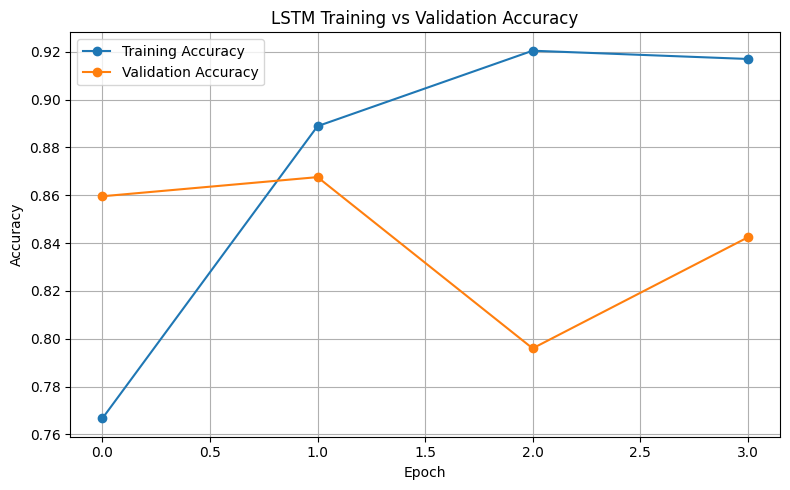

In [15]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], marker="o", label="Training Accuracy")
plt.plot(history.history["val_accuracy"], marker="o", label="Validation Accuracy")
plt.title("LSTM Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

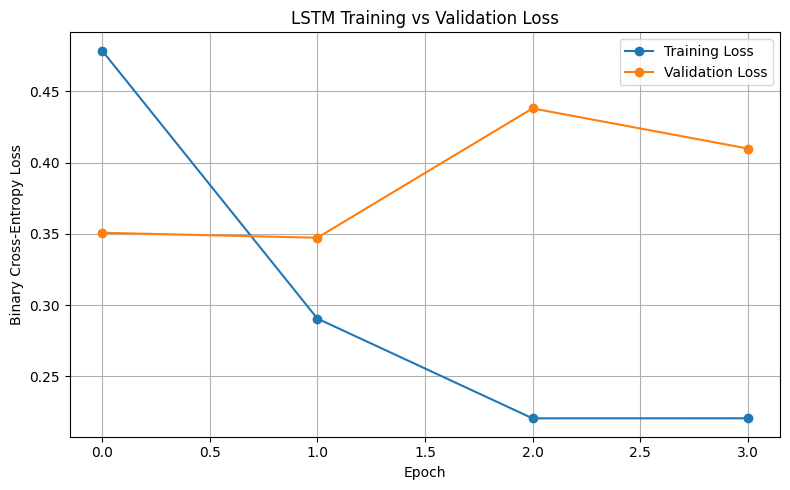

In [16]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], marker="o", label="Training Loss")
plt.plot(history.history["val_loss"], marker="o", label="Validation Loss")
plt.title("LSTM Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [17]:
test_loss, test_accuracy = model.evaluate(X_test_pad, y_test, verbose=0)
y_probability = model.predict(X_test_pad, verbose=0).ravel()
y_pred = (y_probability >= 0.5).astype(int)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

metrics_df = pd.DataFrame({
    "Metric": ["Test Loss", "Accuracy", "Precision", "Recall", "F1 Score"],
    "Value": [test_loss, accuracy, precision, recall, f1]
})

display(metrics_df)
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["Negative", "Positive"],
    zero_division=0
))

,Metric,Value
0,Test Loss,0.379947
1,Accuracy,0.847640
2,Precision,0.846780
3,Recall,0.848880
4,F1 Score,0.847829



Classification Report:
              precision    recall  f1-score   support

    Negative       0.85      0.85      0.85     12500
    Positive       0.85      0.85      0.85     12500

    accuracy                           0.85     25000
   macro avg       0.85      0.85      0.85     25000
weighted avg       0.85      0.85      0.85     25000



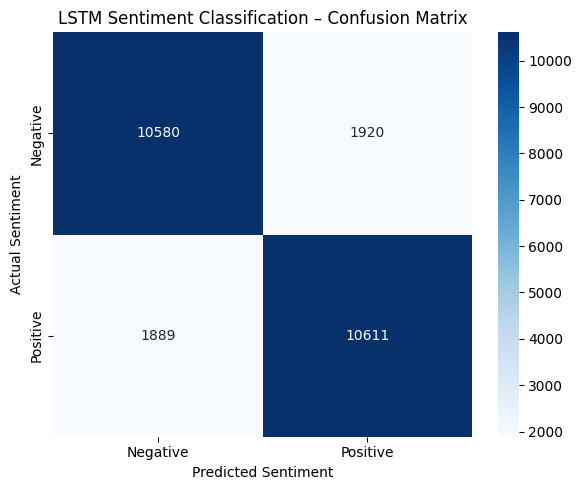

In [18]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("LSTM Sentiment Classification – Confusion Matrix")
plt.tight_layout()
plt.show()

In [19]:
comparison_df = pd.DataFrame({
    "Actual Sentiment": ["Positive" if value == 1 else "Negative" for value in y_test[:20]],
    "Predicted Sentiment": ["Positive" if value == 1 else "Negative" for value in y_pred[:20]],
    "Positive Probability": np.round(y_probability[:20], 4)
})
display(comparison_df)

,Actual Sentiment,Predicted Sentiment,Positive Probability
0,Negative,Negative,0.0261
1,Positive,Positive,0.9801
2,Positive,Positive,0.9215
3,Negative,Negative,0.3008
4,Positive,Positive,0.9416
5,Positive,Positive,0.9018
6,Positive,Positive,0.6815
7,Negative,Negative,0.0192
8,Negative,Positive,0.9390
9,Positive,Positive,0.7504


In [23]:
new_reviews = [
    "The movie was amazing and I loved every scene.",
    "The story was boring and the acting was disappointing.",
    "Not a good movie, I did not enjoy it.",
]

new_clean = [clean_text(review) for review in new_reviews]
new_sequences = tokenizer.texts_to_sequences(new_clean)
new_padded = pad_sequences(
    new_sequences,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

new_probabilities = model.predict(new_padded, verbose=0).ravel()

for review, probability in zip(new_reviews, new_probabilities):
    predicted_sentiment = "Positive" if probability >= 0.5 else "Negative"
    print("Review:", review)
    print("Predicted sentiment:", predicted_sentiment)
    print("Positive probability:", round(float(probability), 4))
    print("-" * 70)

Review: The movie was amazing and I loved every scene.
Predicted sentiment: Positive
Positive probability: 0.9038
----------------------------------------------------------------------
Review: The story was boring and the acting was disappointing.
Predicted sentiment: Negative
Positive probability: 0.0384
----------------------------------------------------------------------
Review: Not a good movie, I did not enjoy it.
Predicted sentiment: Positive
Positive probability: 0.6796
----------------------------------------------------------------------


## 5. Performance analysis and discussion

### 5.1 Impact of sequence length

The notebook uses a maximum sequence length of **200 tokens**. Shorter sequences reduce computation but may truncate useful context from long reviews. Longer sequences retain more text but increase memory use and training time. Padding makes all sequences the same length so they can be processed in batches.

### 5.2 Importance of the Embedding layer

The Embedding layer converts integer word IDs into trainable dense vectors. These vectors can capture useful relationships between words for the sentiment task. Unlike sparse BoW and TF-IDF features, embeddings are learned jointly with the LSTM model.

### 5.3 Effect of LSTM memory cells

LSTM uses a cell state and input, forget and output gates. These mechanisms regulate what information is stored, discarded and exposed at each time step. They help the model learn longer-range dependencies compared with a basic recurrent unit.

### 5.4 Overfitting and possible solutions

Overfitting occurs when training performance continues to improve while validation performance stops improving or becomes worse. The notebook uses Dropout and EarlyStopping. Other possible approaches include reducing model complexity, adding more training data, using regularization and tuning the sequence length or vocabulary size.

### 5.5 Limitations

- The IMDB dataset contains movie reviews, so performance may not transfer directly to other domains such as product, restaurant or service reviews.
- The dataset is supplied as pre-tokenized text; decoding it reconstructs text from the dataset's vocabulary and does not restore the exact original raw review formatting.
- The model learns statistical patterns from its training data and may misunderstand sarcasm, mixed opinions, domain-specific language or subtle context.
- A single sigmoid output simplifies sentiment into only positive or negative classes and does not represent neutral or mixed sentiment.

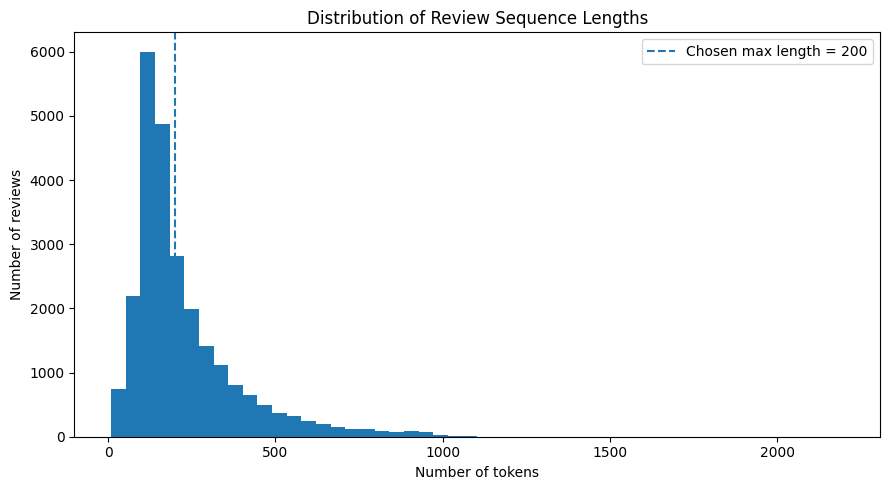

Median sequence length: 170
90th percentile: 439
95th percentile: 575
Percentage longer than MAX_LEN: 39.97 %


In [21]:
train_lengths = [len(sequence) for sequence in X_train_sequences]

plt.figure(figsize=(9, 5))
plt.hist(train_lengths, bins=50)
plt.axvline(MAX_LEN, linestyle="--", label=f"Chosen max length = {MAX_LEN}")
plt.title("Distribution of Review Sequence Lengths")
plt.xlabel("Number of tokens")
plt.ylabel("Number of reviews")
plt.legend()
plt.tight_layout()
plt.show()

print("Median sequence length:", int(np.median(train_lengths)))
print("90th percentile:", int(np.percentile(train_lengths, 90)))
print("95th percentile:", int(np.percentile(train_lengths, 95)))
print("Percentage longer than MAX_LEN:",
      round(100 * np.mean(np.array(train_lengths) > MAX_LEN), 2), "%")

## 17. Save the trained model and tokenizer

In [22]:
from pathlib import Path
import pickle

output_dir = Path("artifacts")
output_dir.mkdir(exist_ok=True)

model.save(output_dir / "imdb_lstm_sentiment.keras")

with open(output_dir / "imdb_tokenizer.pkl", "wb") as file:
    pickle.dump(tokenizer, file)

print("Saved model and tokenizer in:", output_dir.resolve())

Saved model and tokenizer in: F:\Entri\Codes\Assignment\Assignment 11 - Sentiment Analysis using LSTM\artifacts
